<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

Počet objednávok: 196
Najstaršia objednávka: 1996-07-04 00:00:00
Najnovšia objednávka: 1997-02-12 00:00:00

Počet objednávok podľa roku:
orderdate
1996    152
1997     44
Name: count, dtype: int64

Počet objednávok podľa mesiaca:
orderdate
1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
1996-12    31
1997-01    33
1997-02    11
Freq: M, Name: count, dtype: int64


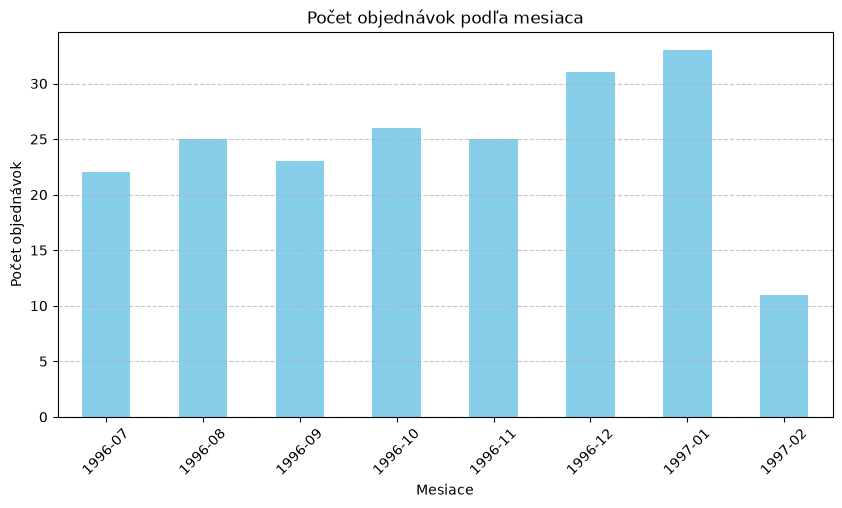

In [3]:
# Vaše riešenie
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv('orders.csv', parse_dates=['orderdate'])


print(f"Počet objednávok: {len(df)}")
print(f"Najstaršia objednávka: {df['orderdate'].min()}")
print(f"Najnovšia objednávka: {df['orderdate'].max()}")


print("\nPočet objednávok podľa roku:")
print(df['orderdate'].dt.year.value_counts().sort_index())


print("\nPočet objednávok podľa mesiaca:")
monthly_counts = df['orderdate'].dt.to_period('M').value_counts().sort_index()
print(monthly_counts)


monthly_counts.plot(kind='bar', figsize=(10, 5), color='skyblue')
plt.title('Počet objednávok podľa mesiaca')
plt.xlabel('Mesiace')
plt.ylabel('Počet objednávok')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [4]:

cutoff_date = '1997-01-01'


historical_orders = df[df['orderdate'] < cutoff_date]
new_orders = df[df['orderdate'] >= cutoff_date]


print(f"Počet historických objednávok: {len(historical_orders)}")
print(f"Počet nových objednávok: {len(new_orders)}")
print(f"Súčet oboch skupín: {len(historical_orders) + len(new_orders)}")
print(f"Celkový počet v pôvodnom dataframe: {len(df)}")


assert len(historical_orders) + len(new_orders) == len(df), "Súčet nesedí s celkovým počtom!"
print("\nOverenie prebehlo úspešne: Obe skupiny spolu obsahujú všetky objednávky.")


Počet historických objednávok: 152
Počet nových objednávok: 44
Súčet oboch skupín: 196
Celkový počet v pôvodnom dataframe: 196

Overenie prebehlo úspešne: Obe skupiny spolu obsahujú všetky objednávky.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [15]:
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

PWD = "Student"

def make_engine(db, **kw):
    url = URL.create(
        "postgresql+psycopg2",
        username="postgres",
        password=PWD,
        host="localhost",
        port=5432,
        database=db,
    )
    return create_engine(url, **kw)

admin = make_engine("postgres", isolation_level="AUTOCOMMIT")
with admin.connect() as c:
    existuje = c.execute(text("SELECT 1 FROM pg_database WHERE datname='northwind'")).scalar()
    if not existuje:
        c.execute(text("CREATE DATABASE northwind"))

engine = make_engine("northwind")

df = pd.read_csv("orders.csv")
with engine.begin() as c:
    c.execute(text("DROP TABLE IF EXISTS orders"))
df.to_sql("orders", engine, if_exists="append", index=False)
with engine.begin() as c:
    c.execute(text("ALTER TABLE orders ADD PRIMARY KEY (orderid)"))

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [17]:
import pandas as pd
df = pd.read_csv("orders.csv")

df["orderdate"] = pd.to_datetime(df["orderdate"])
CUTOFF = pd.Timestamp("1997-07-01")
historical = df[df["orderdate"] < CUTOFF].copy()

pocet_objednavok = len(historical)
pocet_zakaznikov = historical["customerid"].nunique()
percento_shipper3 = (historical["shipperid"] == 3).sum() / len(historical) * 100

print(f"Počet objednávok: {pocet_objednavok}")
print(f"Počet zákazníkov: {pocet_zakaznikov}")
print(f"Percento objednávok s shipperid = 3: {percento_shipper3:.2f} %")

Počet objednávok: 196
Počet zákazníkov: 74
Percento objednávok s shipperid = 3: 34.69 %


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [19]:
from sqlalchemy import text

SAMPLE_SIZE = 44

query = text("""
    SELECT *
    FROM orders
    WHERE CAST(orderdate AS timestamp) >= :cutoff
    ORDER BY CAST(orderdate AS timestamp), orderid
    LIMIT :limit
""")

with engine.connect() as conn:
    sample = pd.read_sql(query, conn, params={"cutoff": CUTOFF, "limit": SAMPLE_SIZE})

sample["orderdate"] = pd.to_datetime(sample["orderdate"])
print(len(sample))
sample.head()

0


,orderid,customerid,employeeid,orderdate,shipperid


In [23]:
df = pd.read_csv("orders.csv")
df.columns = df.columns.str.lower()
df["orderdate"] = pd.to_datetime(df["orderdate"])
df = df.sort_values(["orderdate", "orderid"]).reset_index(drop=True)

CUTOFF = df["orderdate"].iloc[-44]
print(CUTOFF)

df.to_sql("orders", engine, if_exists="replace", index=False)

with engine.connect() as conn:
    sample = pd.read_sql(query, conn, params={"cutoff": CUTOFF, "limit": SAMPLE_SIZE})

sample["orderdate"] = pd.to_datetime(sample["orderdate"])
events = sample.reset_index(drop=True)
print(len(sample), len(events))

1997-01-01 00:00:00
44 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [24]:
import time


EVENT_DELAY_SEC = 0.04     
MICRO_WINDOW_SEC = 0.30     


events = sample.reset_index(drop=True)


stream_count = 0            
stream_shipper3 = 0         
stream_results = []         
stream_times = []           


mb_count = 0                
mb_shipper3 = 0             
mb_results = []             
mb_times = []              


current_batch_count = 0
current_batch_shipper3 = 0
window_start = None        


batch_result = None
batch_time = None

start_time = None           


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [25]:
# Vaše riešenie

start_time = time.time()
window_start = start_time

for _, row in events.iterrows():
    time.sleep(EVENT_DELAY_SEC)
    now = time.time()
    is_s3 = 1 if row["shipperid"] == 3 else 0

    stream_count += 1
    stream_shipper3 += is_s3
    stream_pct = stream_shipper3 / stream_count * 100
    stream_results.append((now - start_time, stream_count, stream_pct))
    stream_times.append(now - start_time)

    current_batch_count += 1
    current_batch_shipper3 += is_s3

    if now - window_start >= MICRO_WINDOW_SEC:
        mb_count += current_batch_count
        mb_shipper3 += current_batch_shipper3
        mb_pct = mb_shipper3 / mb_count * 100
        mb_results.append((now - start_time, mb_count, mb_pct))
        mb_times.append(now - start_time)
        current_batch_count = 0
        current_batch_shipper3 = 0
        window_start = now

print(stream_results[-1])

(1.804274559020996, 44, 22.727272727272727)


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [26]:
# Vaše riešenie
if current_batch_count > 0:
    now = time.time()
    mb_count += current_batch_count
    mb_shipper3 += current_batch_shipper3
    mb_pct = mb_shipper3 / mb_count * 100
    mb_results.append((now - start_time, mb_count, mb_pct))
    mb_times.append(now - start_time)
    current_batch_count = 0
    current_batch_shipper3 = 0

batch_result = (events["shipperid"] == 3).sum() / len(events) * 100
batch_time = time.time() - start_time

stream_final = stream_results[-1][2]
mb_final = mb_results[-1][2]

print(f"Streaming: {stream_final:.4f} %")
print(f"Micro-batch: {mb_final:.4f} %")
print(f"Batch: {batch_result:.4f} %")
print("Streaming == Batch:", abs(stream_final - batch_result) < 1e-9)
print("Micro-batch == Batch:", abs(mb_final - batch_result) < 1e-9)

Streaming: 22.7273 %
Micro-batch: 22.7273 %
Batch: 22.7273 %
Streaming == Batch: True
Micro-batch == Batch: True


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

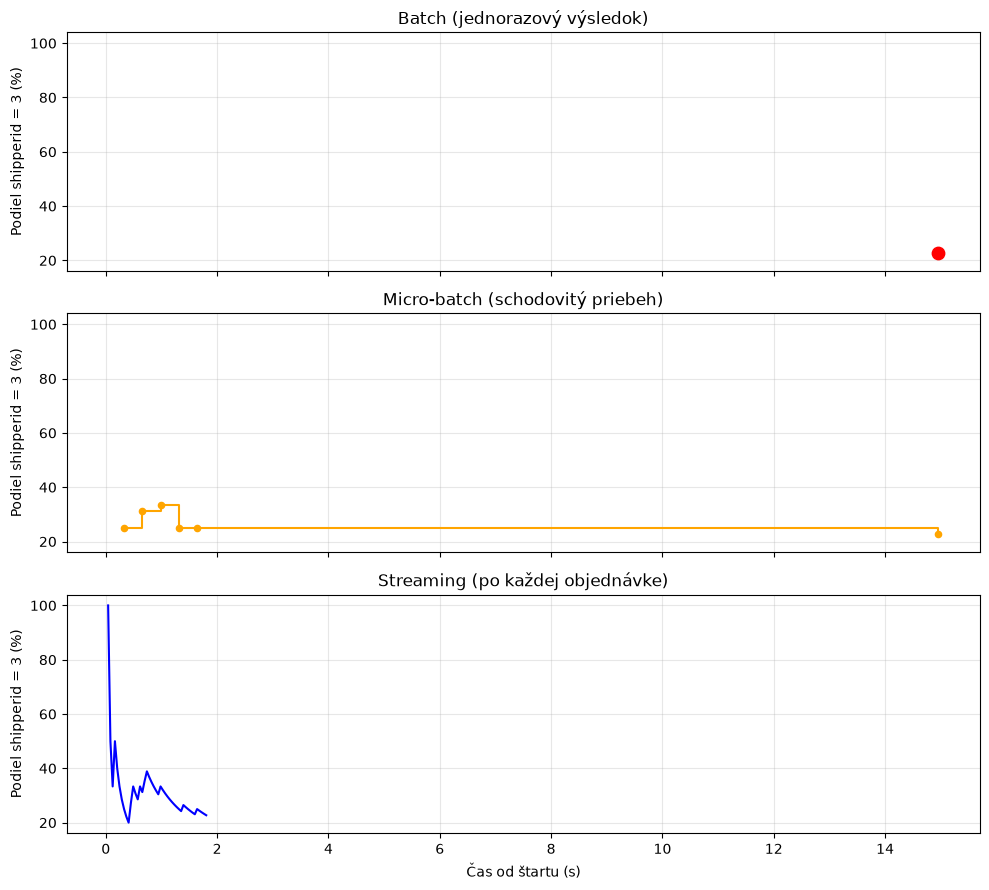

In [27]:
# Vaše riešenie
import matplotlib.pyplot as plt

stream_t = [r[0] for r in stream_results]
stream_p = [r[2] for r in stream_results]
mb_t = [r[0] for r in mb_results]
mb_p = [r[2] for r in mb_results]

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=True)

# 1) Batch: jednorazový bod
axes[0].scatter([batch_time], [batch_result], color="red", s=80, zorder=3)
axes[0].set_title("Batch (jednorazový výsledok)")
axes[0].set_ylabel("Podiel shipperid = 3 (%)")

# 2) Micro-batch: schodovitý priebeh
axes[1].step(mb_t, mb_p, where="post", color="orange")
axes[1].scatter(mb_t, mb_p, color="orange", s=20)
axes[1].set_title("Micro-batch (schodovitý priebeh)")
axes[1].set_ylabel("Podiel shipperid = 3 (%)")

# 3) Streaming: spojitá krivka
axes[2].plot(stream_t, stream_p, color="blue")
axes[2].set_title("Streaming (po každej objednávke)")
axes[2].set_ylabel("Podiel shipperid = 3 (%)")
axes[2].set_xlabel("Čas od štartu (s)")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

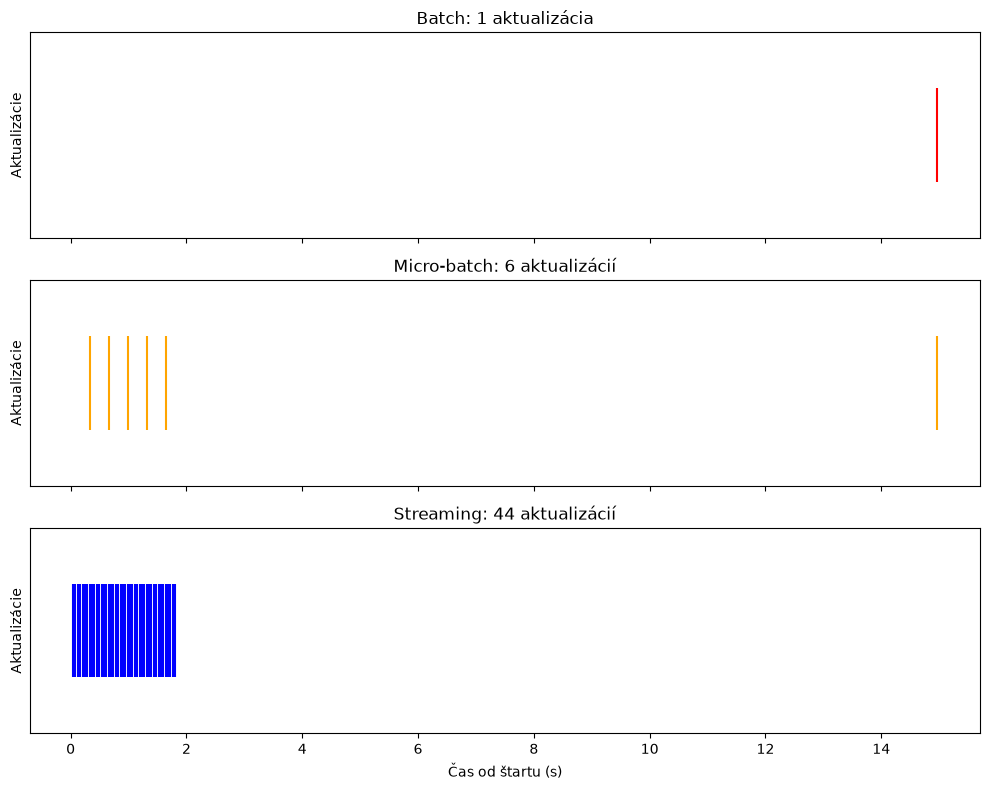

,Prístup,Čas prvého výsledku (s),Počet aktualizácií
0,Batch,14.959,1
1,Micro-batch,0.328,6
2,Streaming,0.042,44


In [28]:
# Vaše riešenie
import matplotlib.pyplot as plt
import pandas as pd

stream_t = [r[0] for r in stream_results]
mb_t = [r[0] for r in mb_results]


n_batch = 1
n_mb = len(mb_results)
n_stream = len(stream_results)


fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].eventplot([batch_time], colors="red", lineoffsets=1, linelengths=0.8)
axes[0].set_title(f"Batch: {n_batch} aktualizácia")
axes[0].set_ylabel("Aktualizácie")
axes[0].set_yticks([])

axes[1].eventplot(mb_t, colors="orange", lineoffsets=1, linelengths=0.8)
axes[1].set_title(f"Micro-batch: {n_mb} aktualizácií")
axes[1].set_ylabel("Aktualizácie")
axes[1].set_yticks([])

axes[2].eventplot(stream_t, colors="blue", lineoffsets=1, linelengths=0.8)
axes[2].set_title(f"Streaming: {n_stream} aktualizácií")
axes[2].set_ylabel("Aktualizácie")
axes[2].set_yticks([])
axes[2].set_xlabel("Čas od štartu (s)")

plt.tight_layout()
plt.show()


first_result = pd.DataFrame({
    "Prístup": ["Batch", "Micro-batch", "Streaming"],
    "Čas prvého výsledku (s)": [batch_time, mb_t[0], stream_t[0]],
    "Počet aktualizácií": [n_batch, n_mb, n_stream],
})
first_result["Čas prvého výsledku (s)"] = first_result["Čas prvého výsledku (s)"].round(3)
first_result

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>